# **PRAKTIKUM 1**

**Langkah 0 - Persiapan Data**

In [127]:
import os
import warnings
os.environ['OMP_NUM_THREADS'] = '1'
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

df = pd.read_csv('../Data/Iris.csv')

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


**Langkah 1 - Seleksi Fitur**

In [128]:
X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]

print(X.head())

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2


**Langkah 2 - Visualisasi Data Awal**

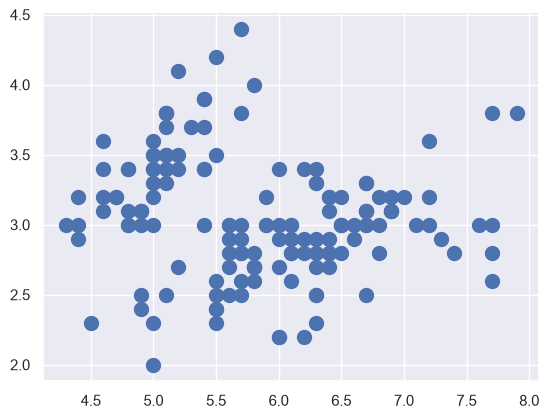

In [129]:
# Plot Data
# Karena data 4 dimensi, maka akan kita coba
# plot cluster berdasarkan Sepal Length dan Sepal Width  saja

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100)

**Langkah 3 - Membuat Model K-Means**

In [130]:
# Buat Model KMeans
# Kali ini kita coba menggunakan k=2 - anggap saja kita tidak tahu jumlah label ada 3 :)

from sklearn.cluster import KMeans

# Inisiasi obyek KMeans
cl_kmeans = KMeans(n_clusters=2)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)

**Langkah 4 - Visualisasi Hasil Clustering**

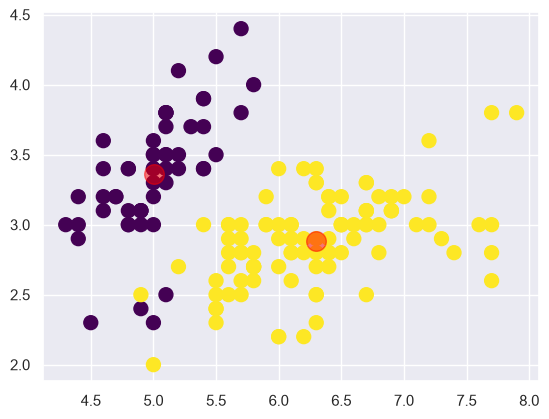

In [131]:
y_plot = 1 - y_kmeans
# Plot hasi cluster berdasarkan Sepal Length dan Sepal Width
plt.scatter(X.iloc[:, 0], X.iloc[:, 1],cmap='viridis', s = 100, c=y_plot)

# Plot centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

**Langkah 5 - Menghitung Nilai SSE**

In [132]:
# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.36870647733906


**Langkah 6 - Implementasi Metode Elbow**

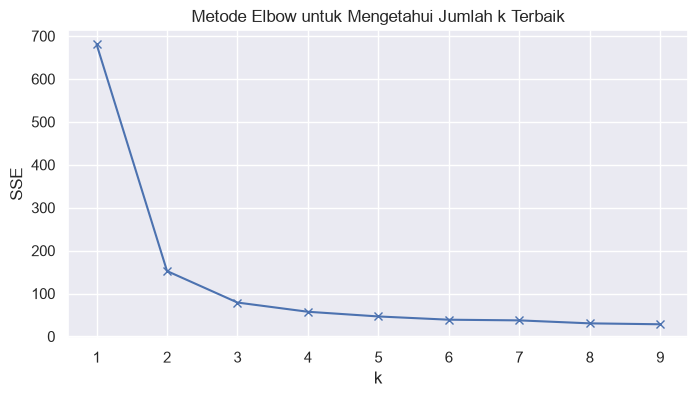

In [133]:
# Implementasi Metode Elbow

# List nilai SSE
sse = []

# Cari k terbaik dari 1-10
K = range(1,10)

# Cek nilai SSE setiap k
for k in K:
 kmeanModel = KMeans(n_clusters=k)
 kmeanModel.fit(X)
 sse.append(kmeanModel.inertia_)


# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

**Langkah 7 - Menampilkan Nilai SSE Setiap k**

In [134]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=680.8244
k=2; SSE=152.36870647733906
k=3; SSE=78.9450658259773
k=4; SSE=57.47327326549492
k=5; SSE=46.535582051282056
k=6; SSE=38.94595367106238
k=7; SSE=37.386770286576166
k=8; SSE=30.45799197860963
k=9; SSE=28.31544008929879


# **PRAKTIKUM 2**

**Langkah 0 - Import Library**

In [135]:
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np

## **Pengantar k-Means**

**Langkah 1 - Membuat Dataset Sintetis**

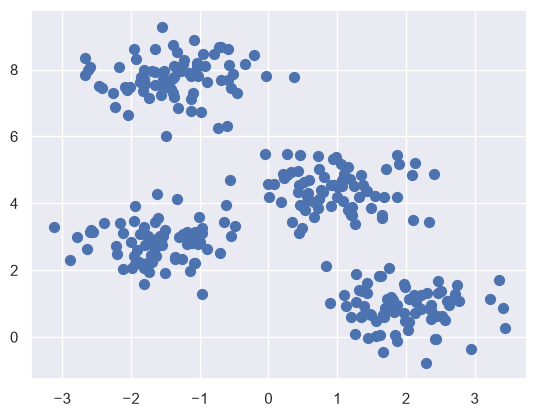

In [136]:
from sklearn.datasets import make_blobs
X, y_true = make_blobs(n_samples=300, centers=4,
                       cluster_std=0.60, random_state=0)
plt.scatter(X[:, 0], X[:, 1], s=50)

**Langkah 2 - Membuat Model K-Means**

In [137]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4,random_state = 1)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

**Langkah 3 - Visualisasi Hasil Clustering**

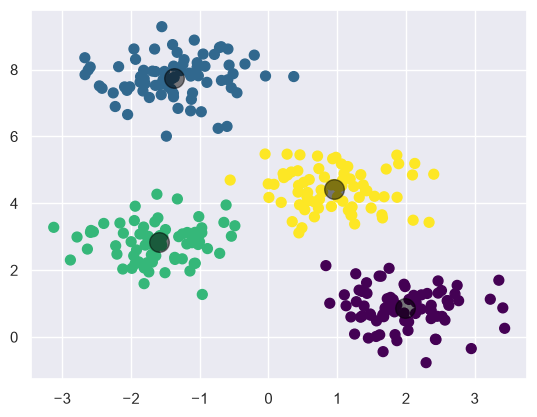

In [138]:
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)

## **Algoritma Expectation-Maximization**

**Langkah 4 - Implementasi K-Means Secara Manual**

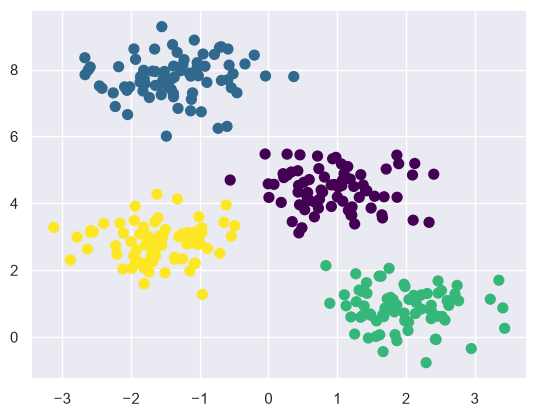

In [139]:
from sklearn.metrics import pairwise_distances_argmin

def find_clusters(X, n_clusters, rseed=2):
    # 1. Randomly choose clusters
    rng = np.random.RandomState(rseed)
    i = rng.permutation(X.shape[0])[:n_clusters]
    centers = X[i]

    while True:
        # 2a. input label center yang baru
        labels = pairwise_distances_argmin(X, centers)

        # 2b. update center dari titik baru
        new_centers = np.array([X[labels == i].mean(0)
                                for i in range(n_clusters)])

        # 2c. cek konvergensi
        if np.all(centers == new_centers):
            break
        centers = new_centers

    return centers, labels

centers, labels = find_clusters(X, 4)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

**Langkah 5 - Mengubah Nilai Random Seed**

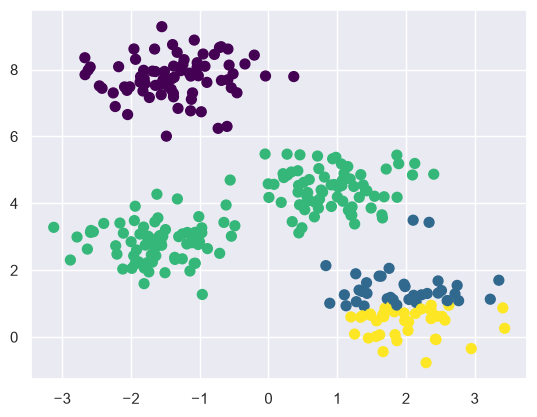

In [140]:
centers, labels = find_clusters(X, 4, rseed=0)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

**Langkah 6 - Mengubah Jumlah Cluster**

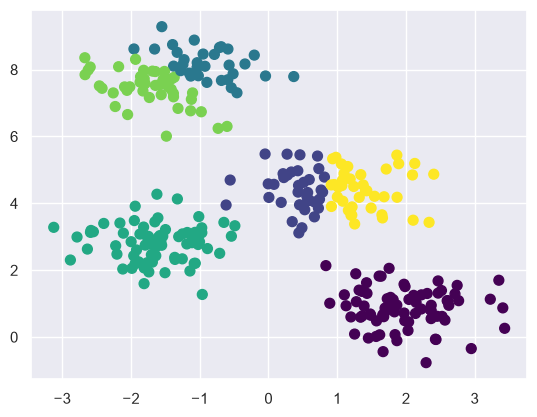

In [141]:
labels = KMeans(6,n_init=10, random_state=80).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

**Langkah 7 - Membuat Dataset Moon**

In [142]:
from sklearn.datasets import make_moons
X, y = make_moons(200, noise=.05, random_state=0)

**Langkah 8 - Clustering dengan K-Means pada Data Moon**

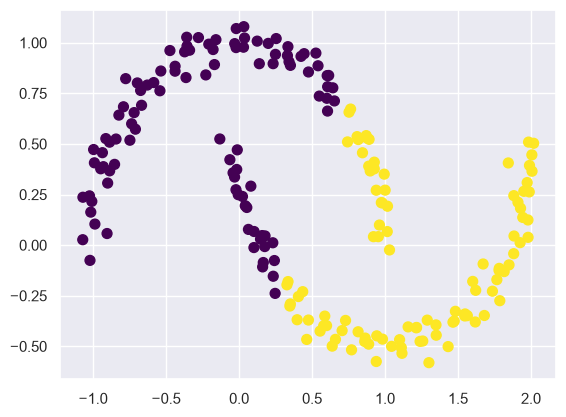

In [143]:
labels = KMeans(2, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

**Langkah 9 - Clustering dengan Spectral Clustering**

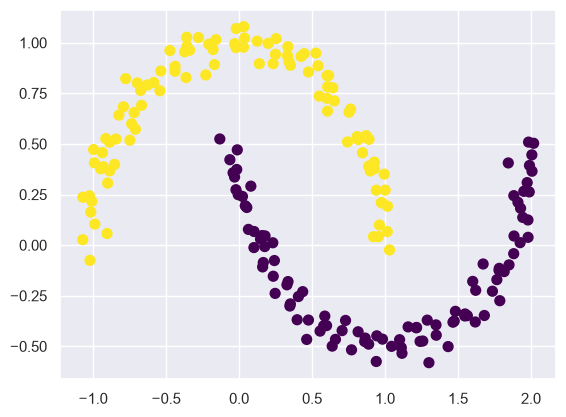

In [144]:
from sklearn.cluster import SpectralClustering
model = SpectralClustering(n_clusters=2, affinity='nearest_neighbors',
                           assign_labels='kmeans', random_state=42)
labels = model.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

## **Studi Kasus 1 - Karakter Angka**

**Langkah 10 - Memuat Dataset Digits**

In [145]:
from sklearn.datasets import load_digits
digits = load_digits()
digits.data.shape

(1797, 64)

**Langkah 11 - Menerapkan K-Means pada Dataset Digits**

In [146]:
# terapkan K-Means
kmeans = KMeans(n_clusters=10,n_init=10,random_state=104)
clusters = kmeans.fit_predict(digits.data)
kmeans.cluster_centers_.shape

(10, 64)

**Langkah 12 - Menampilkan Centroid Angka**

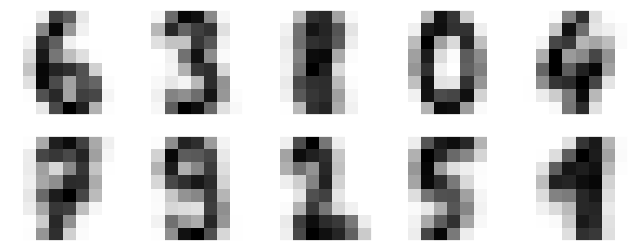

In [147]:
fig, ax = plt.subplots(2, 5, figsize=(8, 3))
centers = kmeans.cluster_centers_.reshape(10, 8, 8)
for axi, center in zip(ax.flat, centers):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary)

**Langkah 13 - Menentukan Label Cluster**

In [148]:
from scipy.stats import mode

labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

**Langkah 14 - Menghitung Akurasi**

In [149]:
from sklearn.metrics import accuracy_score
accuracy_score(digits.target, labels)

0.7935447968836951

**Langkah 15 - Membuat Confusion Matrix**

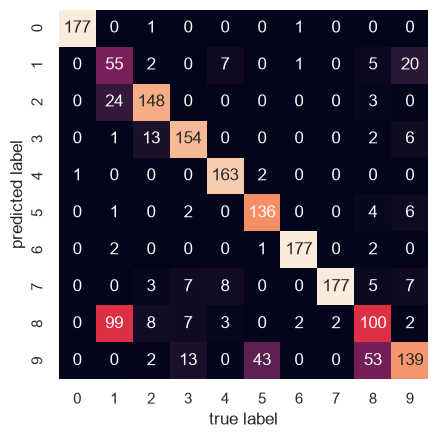

In [150]:
from sklearn.metrics import confusion_matrix
mat = confusion_matrix(digits.target, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=digits.target_names,
            yticklabels=digits.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label');

**Langkah 16 - Reduksi Dimensi dengan t-SNE**

In [151]:
from sklearn.manifold import TSNE


tsne = TSNE(n_components=2, init='random', random_state=42)
digits_proj = tsne.fit_transform(digits.data)

# hitung klaster
kmeans = KMeans(n_clusters=10, n_init=10,random_state=8)
clusters = kmeans.fit_predict(digits_proj)

# permutasi label
labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

# hitung akurasi
accuracy_score(digits.target, labels)

0.9415692821368948

## **Studi Kasus 2 - Kompresi Citra**

**Langkah 17 - Memuat Gambar Sampel**

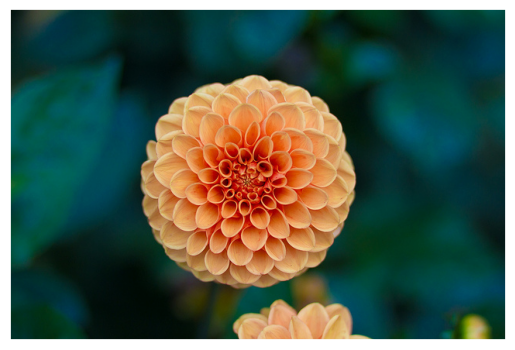

In [152]:
from sklearn.datasets import load_sample_image
flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower);

**Langkah 18 - Melihat Ukuran Gambar**

In [153]:
flower.shape

(427, 640, 3)

**Langkah 19 - Menyiapkan Data Warna**

In [154]:
data = flower / 255.0
data = data.reshape(427 * 640, 3)
data.shape

(273280, 3)

**Langkah 20 - Membuat Fungsi Visualisasi Warna**

In [155]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data

    # choose a random subset
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))

    fig.suptitle(title, size=20);

**Langkah 21 - Menampilkan Ruang Warna Asli**

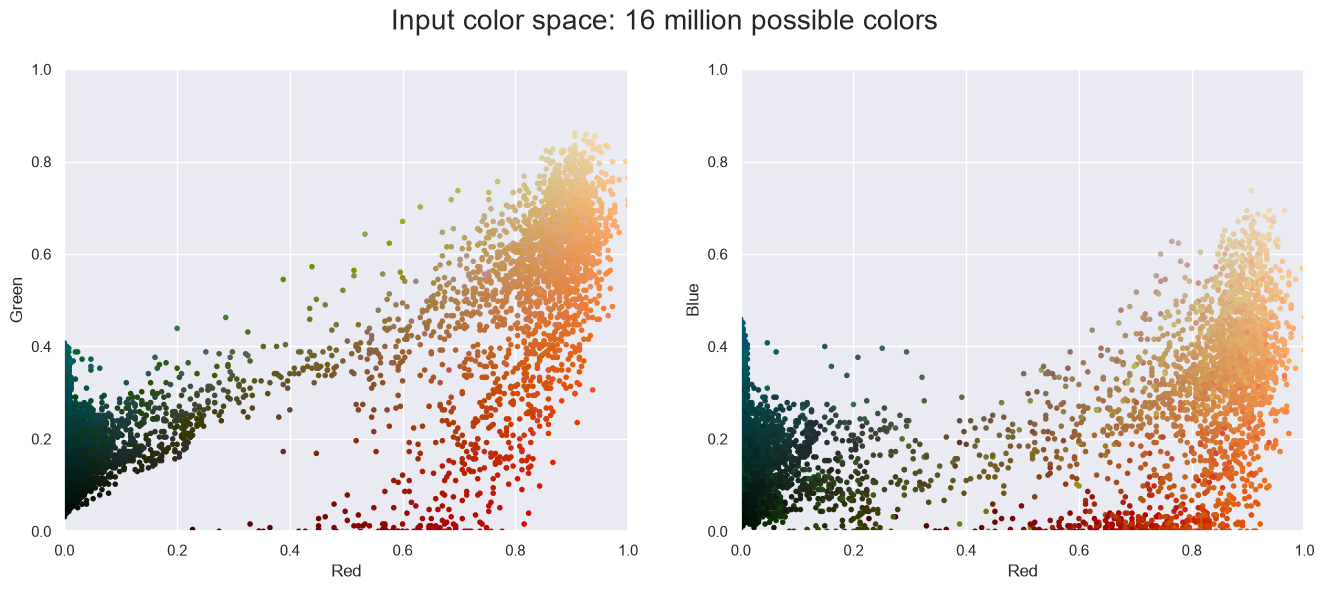

In [156]:
plot_pixels(data, title='Input color space: 16 million possible colors')

**Langkah 22 - Reduksi Warna dengan MiniBatchKMeans**

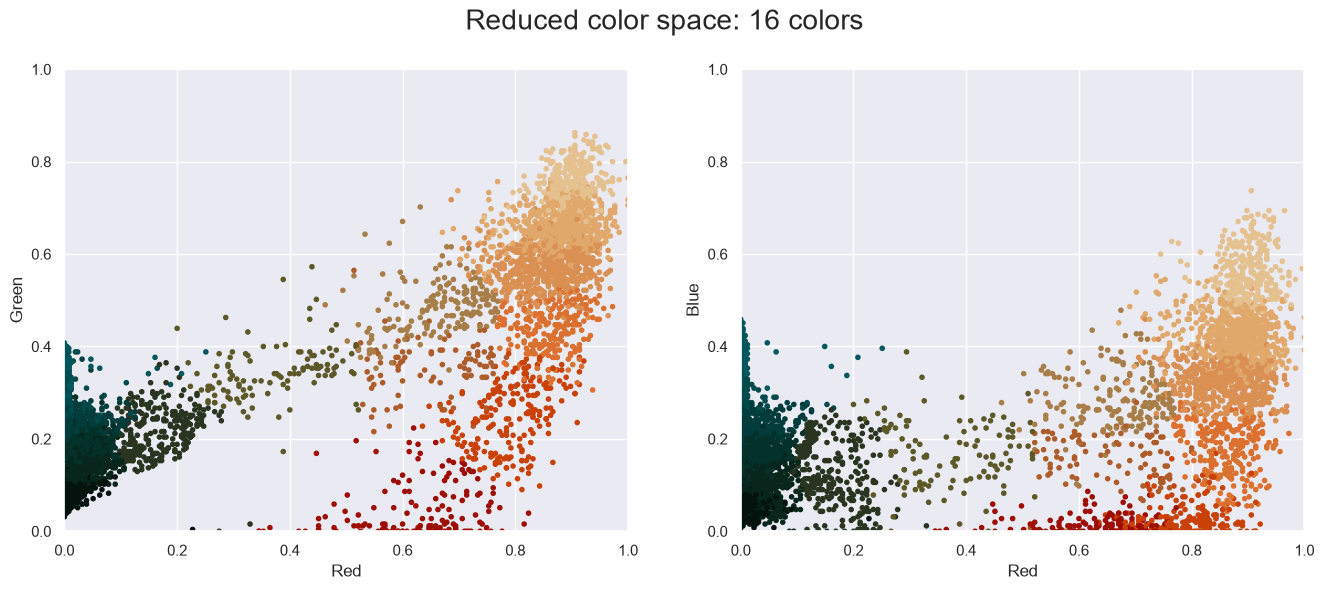

In [157]:
import warnings; warnings.simplefilter('ignore')  # Fix NumPy issues.

from sklearn.cluster import MiniBatchKMeans
kmeans = MiniBatchKMeans(16)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors,title="Reduced color space: 16 colors")

**Langkah 23 - Menampilkan Hasil Kompresi Citra**

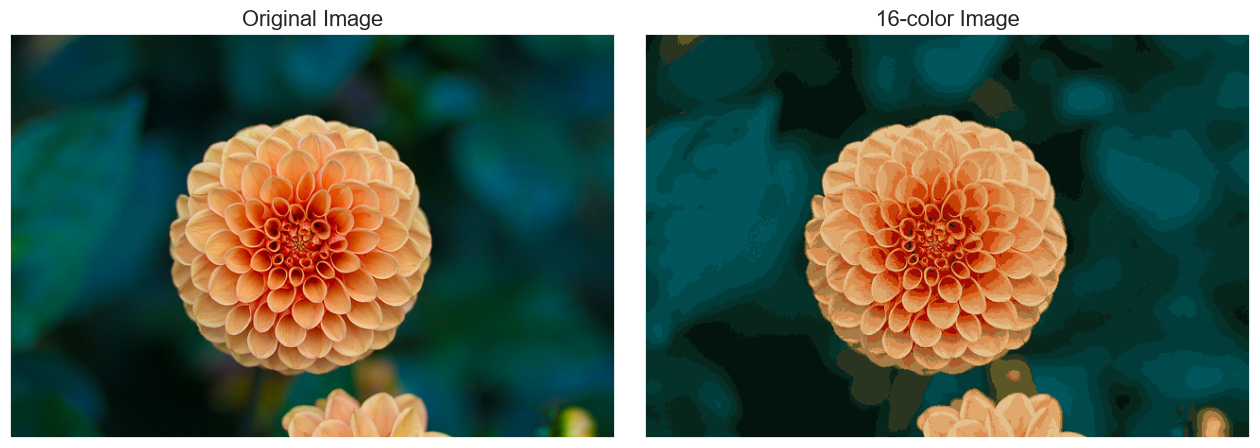

In [158]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16);

# **PRAKTIKUM 3**

**Langkah 0 - Import Library dan Membuat Dataset Sintetis**

In [159]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

centers = [[1, 1], [-1, -1], [1, -1]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=0.4, random_state=0
)

X = StandardScaler().fit_transform(X)

**Langkah 1 - Visualisasi Dataset**

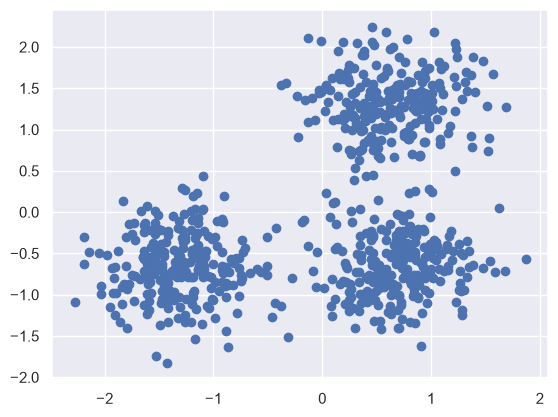

In [160]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1])
plt.show()

## **Implementasi DBSCAN**

**Langkah 2 - Membuat Model DBSCAN**

In [161]:
import numpy as np

from sklearn import metrics
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.3, min_samples=10).fit(X)
labels = db.labels_

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

**Langkah 3 - Menampilkan Jumlah Cluster dan Noise**

In [162]:
print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 3
Estimated number of noise points: 18


*  eps = 0.3 → jarak maksimum antar titik untuk dianggap tetangga.
*  min_samples = 10 → jumlah minimum titik dalam radius eps agar dianggap area padat (core sample).
*  Label hasil klasterisasi tersedia di labels. Nilai -1 berarti titik tersebut dianggap noise atau outlier.

## **Evaluasi Kualitas Clustering**

**Langkah 4 - Menghitung Nilai Evaluasi Clustering**

In [163]:
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(
    "Adjusted Mutual Information:"
    f" {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}"
)
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}")

Homogeneity: 0.953
Completeness: 0.883
V-measure: 0.917
Adjusted Rand Index: 0.952
Adjusted Mutual Information: 0.916
Silhouette Coefficient: 0.626


*  Homogeneity → apakah tiap klaster hanya berisi satu label asli.
Completeness → apakah semua sampel dengan label asli yang sama masuk ke klaster yang sama.
*  V-measure → rata-rata harmonik dari homogeneity dan completeness.
*  Adjusted Rand Index (ARI) → kesesuaian antara klasterisasi dengan label asli.
*  Adjusted Mutual Information (AMI) → kesamaan informasi antara klasterisasi dengan label asli.
*  Silhouette Coefficient → seberapa baik data dikelompokkan (nilai mendekati 1 berarti bagus, mendekati 0 berarti berada di batas, negatif berarti salah klaster).

## **Visualisasi Hasil DBSCAN**

**Langkah 5 - Menentukan Core Sample dan Label Cluster**

In [164]:
unique_labels = set(labels)
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

**Langkah 6 - Menentukan Warna Setiap Cluster**

In [165]:
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

**Langkah 7 - Menampilkan Core Sample dan Non Core Sample**

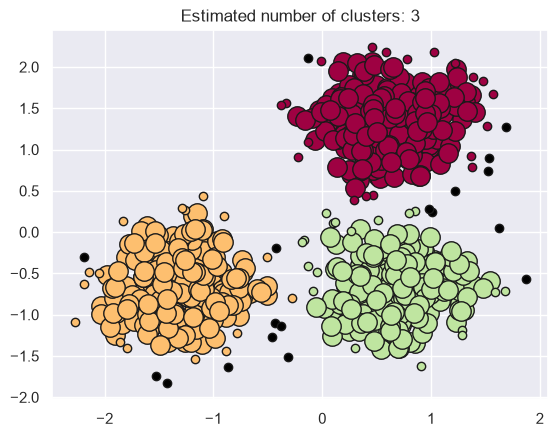

In [166]:
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = [0, 0, 0, 1]

    class_member_mask = labels == k

    xy = X[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=14,
    )
    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6,
    )


plt.title(f"Estimated number of clusters: {n_clusters_}")
plt.show()

Interpretasi visual:

*   Titik besar berwarna → core samples dalam klaster.
*   Titik kecil berwarna → non-core samples, tetap termasuk klaster.
*   Titik hitam → noise/outlier.



# **TUGAS PRAKTIKUM**

## **1. Tugas K-Means**

**Langkah 0 - Import Library**

In [167]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


**Langkah 1 - Membaca Datase**

In [168]:
df = pd.read_csv('../Data/Mall_Customers.csv')

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


**Langkah 2 - Memahami Dataset**

In [169]:
df.info()
print('================================================================')
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


**Langkah 3 - Memilih Fitur Clustering**

In [170]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


**Langkah 4 - Standardisasi Data**

In [171]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

**Langkah 5 - Visualisasi Data Awal**

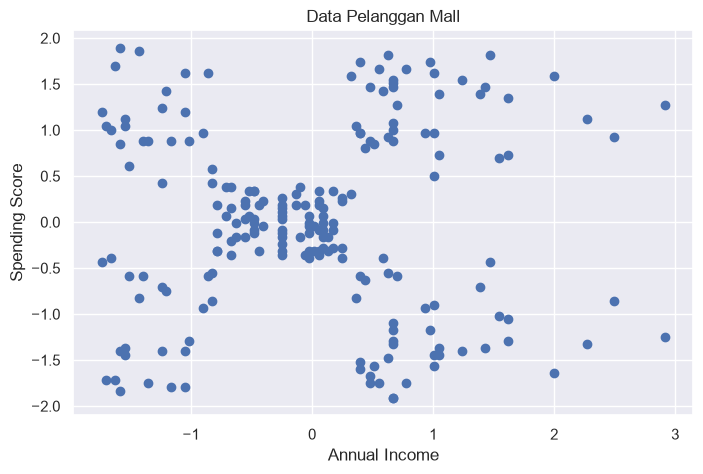

In [172]:
plt.figure(figsize=(8,5))
plt.scatter(X_scaled[:,0], X_scaled[:,1])
plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('Data Pelanggan Mall')
plt.show()

**Langkah 6 - Menentukan Nilai K dengan Metode Elbow**

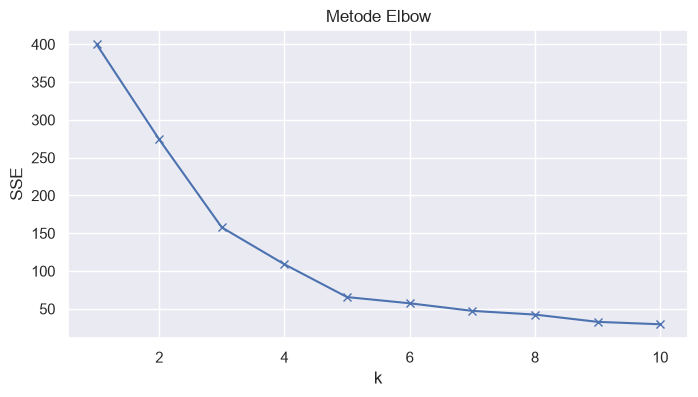

In [173]:
sse = []

K = range(1,11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(X_scaled)
    sse.append(kmeans.inertia_)

plt.figure(figsize=(8,4))
plt.plot(K, sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Metode Elbow')
plt.show()

**Langkah 7 - Menampilkan Nilai SSE**

In [174]:
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=400.00000000000006
k=2; SSE=274.0906128402975
k=3; SSE=157.70400815035944
k=4; SSE=108.92131661364357
k=5; SSE=65.56840815571681
k=6; SSE=57.381747460227864
k=7; SSE=47.33848673638823
k=8; SSE=42.42564554911967
k=9; SSE=32.81363694105777
k=10; SSE=29.618329582146515


**Langkah 8 - Membuat Model K-Means Terbaik**

In [175]:
k_terbaik = 5
kmeans = KMeans(
    n_clusters=k_terbaik,
    random_state=0
)

cluster = kmeans.fit_predict(X_scaled)

**Langkah 9 - Menampilkan Hasil Clustering**

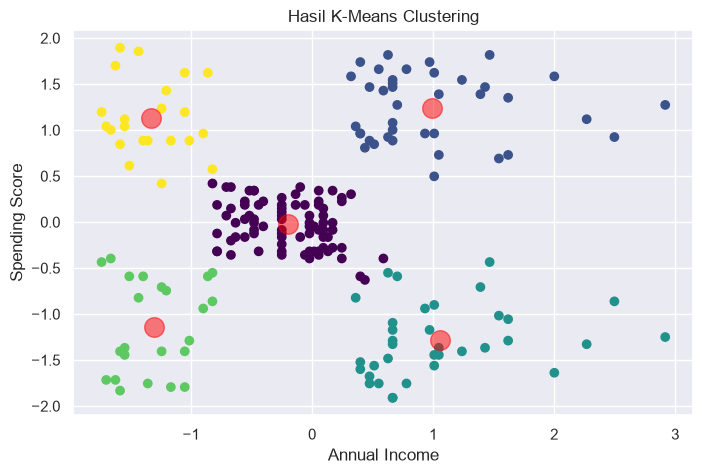

In [176]:
plt.figure(figsize=(8,5))

plt.scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=cluster,
    cmap='viridis'
)

centers = kmeans.cluster_centers_

plt.scatter(
    centers[:,0],
    centers[:,1],
    c='red',
    s=200,
    alpha=0.5
)

plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('Hasil K-Means Clustering')
plt.show()

**Langkah 10 - Menambahkan Label Cluster ke Dataset**

In [177]:
df['Cluster'] = cluster

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,3
1,2,Male,21,15,81,4
2,3,Female,20,16,6,3
3,4,Female,23,16,77,4
4,5,Female,31,17,40,3


**Langkah 11 - Interpretasi Hasil**

In [178]:
df.groupby('Cluster')[['Annual Income (k$)','Spending Score (1-100)']].mean()

,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.296296,49.518519
1,86.538462,82.128205
2,88.200000,17.114286
3,26.304348,20.913043
4,25.727273,79.363636


## **2. Tugas DBSCAN**

**Langkah 0 - Import Library**

In [179]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn import metrics

**Langkah 1 - Membuat Dataset Make Moons**

In [180]:
X, labels_true = make_moons(
    n_samples=1000,
    noise=0.05,
    random_state=0
)

**Langkah 2 - Normalisasi Data**

In [181]:
X = StandardScaler().fit_transform(X)

**Langkah 3 - Visualisasi Dataset**

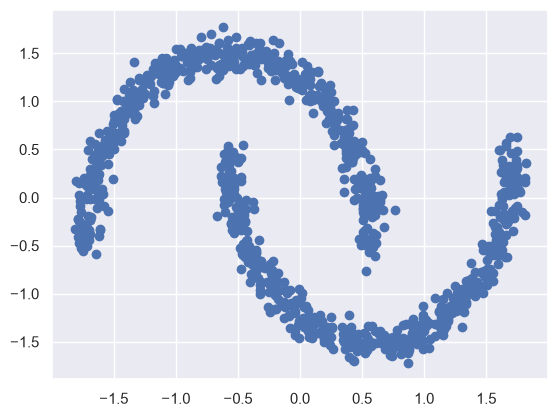

In [182]:
plt.scatter(X[:,0], X[:,1])
plt.show()

**Langkah 4 - Membuat Model DBSCAN**

In [183]:
db = DBSCAN(
    eps=0.2,
    min_samples=5
).fit(X)

labels = db.labels_

**Langkah 5 - Menghitung Jumlah Cluster dan Noise**

In [184]:
n_clusters_ = len(set(labels)) - (
    1 if -1 in labels else 0
)

n_noise_ = list(labels).count(-1)

print("Jumlah Cluster :", n_clusters_)
print("Jumlah Noise :", n_noise_)

Jumlah Cluster : 2
Jumlah Noise : 0


**Langkah 6 - Evaluasi Clustering**

In [185]:
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(
    "Adjusted Mutual Information:"
    f" {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}"
)
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}")

Homogeneity: 1.000
Completeness: 1.000
V-measure: 1.000
Adjusted Rand Index: 1.000
Adjusted Mutual Information: 1.000
Silhouette Coefficient: 0.392


**Langkah 7 - Menentukan Core Sample**

In [186]:
core_samples_mask = np.zeros_like(
    labels,
    dtype=bool
)

core_samples_mask[
    db.core_sample_indices_
] = True

unique_labels = set(labels)

**Langkah 8 - Visualisasi Hasil DBSCAN**

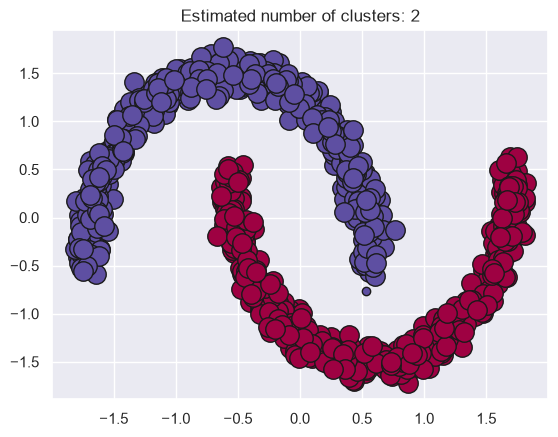

In [187]:
colors = [
    plt.cm.Spectral(each)
    for each in np.linspace(
        0,
        1,
        len(unique_labels)
    )
]

for k, col in zip(unique_labels, colors):

    if k == -1:
        col = [0,0,0,1]

    class_member_mask = (labels == k)

    xy = X[
        class_member_mask
        & core_samples_mask
    ]

    plt.plot(
        xy[:,0],
        xy[:,1],
        'o',
        markerfacecolor=tuple(col),
        markeredgecolor='k',
        markersize=14
    )

    xy = X[
        class_member_mask
        & ~core_samples_mask
    ]

    plt.plot(
        xy[:,0],
        xy[:,1],
        'o',
        markerfacecolor=tuple(col),
        markeredgecolor='k',
        markersize=6
    )

plt.title(
    f'Estimated number of clusters: {n_clusters_}'
)

plt.show()

**Langkah 9 - Eksperimen Parameter DBSCANl**

In [188]:
eps_list = [0.05, 0.1, 0.3, 0.5]
min_samples_list = [3, 10, 20]
hasil = []

for eps in eps_list:

    for min_samp in min_samples_list:

        db = DBSCAN(
            eps=eps,
            min_samples=min_samp
        ).fit(X)

        labels = db.labels_

        # mengitung jumlah cluster dan noise
        n_clusters = len(set(labels)) - (
            1 if -1 in labels else 0
        )

        n_noise = list(labels).count(-1)

        # mengecek apakah silhouette score bisa dihitung
        if n_clusters > 1:
            silhouette = metrics.silhouette_score(
                X,
                labels
            )
        else:
            silhouette = np.nan

        hasil.append([
            eps,
            min_samp,
            n_clusters,
            n_noise,
            metrics.homogeneity_score(labels_true,labels),
            metrics.completeness_score(labels_true,labels),
            metrics.v_measure_score(labels_true,labels),
            metrics.adjusted_rand_score(labels_true,labels),
            metrics.adjusted_mutual_info_score(labels_true,labels),
            silhouette
        ])

**Langkah 10 - Menampilkan Hasil Eksperimen**

In [189]:
hasil_df = pd.DataFrame(
    hasil,
    columns=[
        'eps',
        'min_samples',
        'cluster',
        'noise',
        'homogeneity',
        'completeness',
        'v_measure',
        'ARI',
        'AMI',
        'silhouette'
    ]
)

hasil_df

,eps,min_samples,cluster,noise,homogeneity,completeness,v_measure,ARI,AMI,silhouette
0,0.05,3,67,197,0.803825,0.154915,0.259767,0.032984,0.246428,0.077967
1,0.05,10,0,1000,0.000000,1.000000,0.000000,0.000000,0.000000,NaN
2,0.05,20,0,1000,0.000000,1.000000,0.000000,0.000000,0.000000,NaN
3,0.10,3,3,18,0.983471,0.708395,0.823571,0.854285,0.823246,0.137887
4,0.10,10,9,63,0.938949,0.358282,0.518656,0.435052,0.516899,0.184140
5,0.10,20,6,844,0.157108,0.153385,0.155224,0.010402,0.151519,-0.409118
6,0.30,3,2,0,1.000000,1.000000,1.000000,1.000000,1.000000,0.391597
7,0.30,10,2,0,1.000000,1.000000,1.000000,1.000000,1.000000,0.391597
8,0.30,20,2,0,1.000000,1.000000,1.000000,1.000000,1.000000,0.391597
9,0.50,3,1,0,0.000000,1.000000,0.000000,0.000000,0.000000,NaN


Berdasarkan hasil eksperimen, parameter terbaik untuk dataset make_moons adalah eps = 0.30 dengan min_samples = 3, 10, atau 20. Pada kombinasi parameter tersebut, DBSCAN berhasil menemukan 2 cluster tanpa noise dan menghasilkan seluruh metrik evaluasi sebesar 1.000, yang menunjukkan bahwa hasil clustering identik dengan label asli dataset.

Sedangkan nilai NaN pada Silhouette Score muncul ketika jumlah cluster yang dihasilkan tidak memenuhi syarat perhitungan, yaitu ketika tidak ada cluster atau hanya terdapat satu cluster saja.